## 1. Load cleaned data

In [3]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent

CLEAN_FILE = PROJECT_ROOT / "data" / "processed" / "superstore_clean.csv"

df = pd.read_csv(
    CLEAN_FILE,
    parse_dates=["order_date", "ship_date", "month_start"]
)

print("Dataset loaded:", df.shape)

Dataset loaded: (9994, 29)


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 29 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   row_id         9994 non-null   int64         
 1   order_id       9994 non-null   str           
 2   order_date     9994 non-null   datetime64[us]
 3   ship_date      9994 non-null   datetime64[us]
 4   ship_mode      9994 non-null   str           
 5   customer_id    9994 non-null   str           
 6   customer_name  9994 non-null   str           
 7   segment        9994 non-null   str           
 8   country        9994 non-null   str           
 9   city           9994 non-null   str           
 10  state          9994 non-null   str           
 11  postal_code    9994 non-null   int64         
 12  region         9994 non-null   str           
 13  product_id     9994 non-null   str           
 14  category       9994 non-null   str           
 15  sub_category   9994 non-null   s

## 2. Overall KPIs

In [3]:
total_revenue = df["revenue"].sum()
total_profit = df["profit"].sum()
total_orders = df["order_id"].nunique()
total_customers = df["customer_id"].nunique()
total_products = df["product_id"].nunique()
total_units = df["quantity"].sum()

overall_profit_margin = total_profit / total_revenue * 100
average_order_value = total_revenue / total_orders
revenue_per_customer = total_revenue / total_customers

print("Total Revenue:", round(total_revenue, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Products:", total_products)
print("Total Units Sold:", total_units)
print("Overall Profit Margin:", round(overall_profit_margin, 2), "%")
print("Average Order Value:", round(average_order_value, 2))
print("Average Revenue per Customer:", round(revenue_per_customer, 2))

Total Revenue: 2297200.86
Total Profit: 286397.02
Total Orders: 5009
Total Customers: 793
Total Products: 1862
Total Units Sold: 37873
Overall Profit Margin: 12.47 %
Average Order Value: 458.61
Average Revenue per Customer: 2896.85


In [4]:
print("Start Date:", df["order_date"].min())
print("End Date:", df["order_date"].max())

# Number of order lines (rows) per year
df["year"].value_counts().sort_index()

Start Date: 2014-01-03 00:00:00
End Date: 2017-12-30 00:00:00


year
2014    1993
2015    2102
2016    2587
2017    3312
Name: count, dtype: int64

## 3. Annual performance

In [5]:
annual_performance = (
    df.groupby("year")
      .agg(
          revenue=("revenue", "sum"),
          profit=("profit", "sum"),
          orders=("order_id", "nunique"),
          customers=("customer_id", "nunique"),
          units=("quantity", "sum")
      )
      .reset_index()
)

annual_performance["profit_margin"] = (
    annual_performance["profit"]
    / annual_performance["revenue"]
    * 100
)

annual_performance["revenue_growth"] = (
    annual_performance["revenue"].pct_change() * 100
)

annual_performance["profit_growth"] = (
    annual_performance["profit"].pct_change() * 100
)

annual_performance

,year,revenue,profit,orders,customers,units,profit_margin,revenue_growth,profit_growth
0,2014,484247.4981,49543.9741,969,595,7581,10.231126,NaN,NaN
1,2015,470532.5090,61618.6037,1038,573,7979,13.095504,-2.832227,24.371540
2,2016,609205.5980,81795.1743,1315,638,9837,13.426530,29.471521,32.744284
3,2017,733215.2552,93439.2696,1687,693,12476,12.743771,20.355962,14.235675


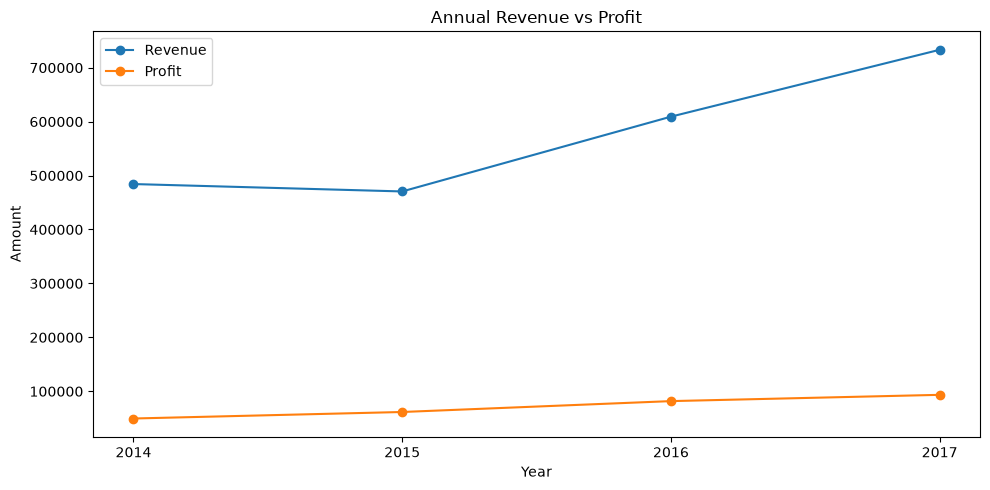

In [6]:
plt.figure(figsize=(10, 5))

plt.plot(
    annual_performance["year"],
    annual_performance["revenue"],
    marker="o",
    label="Revenue"
)

plt.plot(
    annual_performance["year"],
    annual_performance["profit"],
    marker="o",
    label="Profit"
)

plt.title("Annual Revenue vs Profit")
plt.xlabel("Year")
plt.ylabel("Amount")
plt.xticks(annual_performance["year"])

plt.legend()
plt.tight_layout()
plt.show()

## 4. Monthly performance

In [7]:
monthly_performance = (
    df.groupby("month_start")
      .agg(
          revenue=("revenue", "sum"),
          profit=("profit", "sum"),
          orders=("order_id", "nunique"),
          customers=("customer_id", "nunique"),
          units=("quantity", "sum")
      )
      .reset_index()
)

monthly_performance["profit_margin"] = (
    monthly_performance["profit"]
    / monthly_performance["revenue"]
    * 100
)

monthly_performance["revenue_mom_growth"] = (
    monthly_performance["revenue"].pct_change() * 100
)

monthly_performance.head(12)

,month_start,revenue,profit,orders,customers,units,profit_margin,revenue_mom_growth
0,2014-01-01,14236.8950,2450.1907,32,32,284,17.210148,NaN
1,2014-02-01,4519.8920,862.3084,28,27,159,19.078075,-68.252263
2,2014-03-01,55691.0090,498.7299,71,69,585,0.895530,1132.131409
3,2014-04-01,28295.3450,3488.8352,66,64,536,12.330068,-49.192257
4,2014-05-01,23648.2870,2738.7096,69,67,466,11.581006,-16.423401
5,2014-06-01,34595.1276,4976.5244,66,63,521,14.385044,46.290205
6,2014-07-01,33946.3930,-841.4826,65,65,550,-2.478857,-1.875220
7,2014-08-01,27909.4685,5318.1050,72,70,609,19.054842,-17.783699
8,2014-09-01,81777.3508,8328.0994,130,118,1000,10.183870,193.009345
9,2014-10-01,31453.3930,3448.2573,78,75,573,10.963069,-61.537770


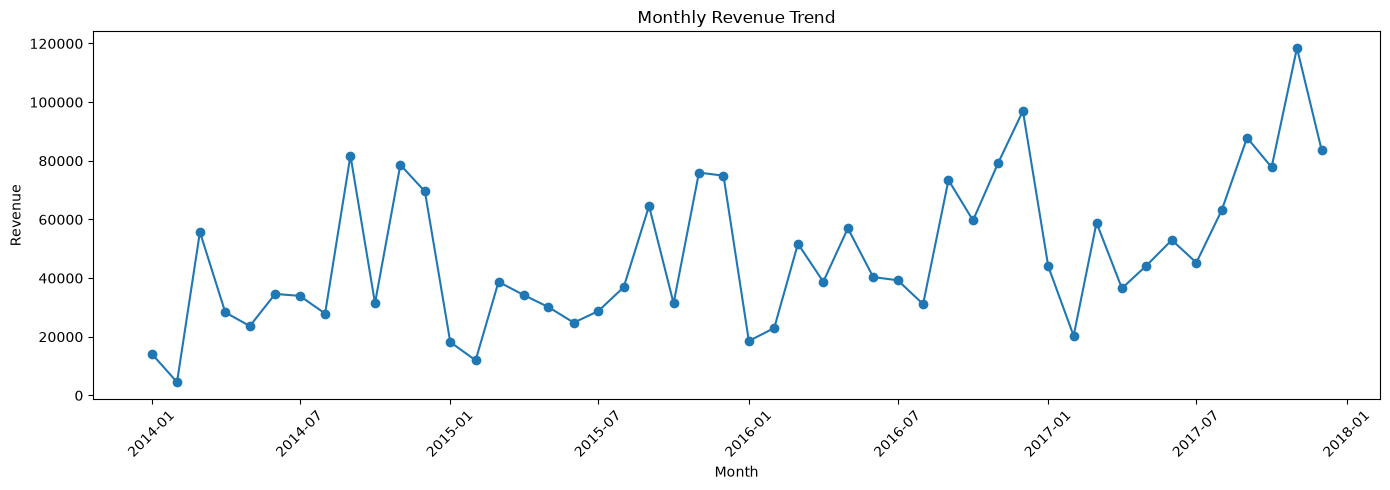

In [8]:
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_performance["month_start"],
    monthly_performance["revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

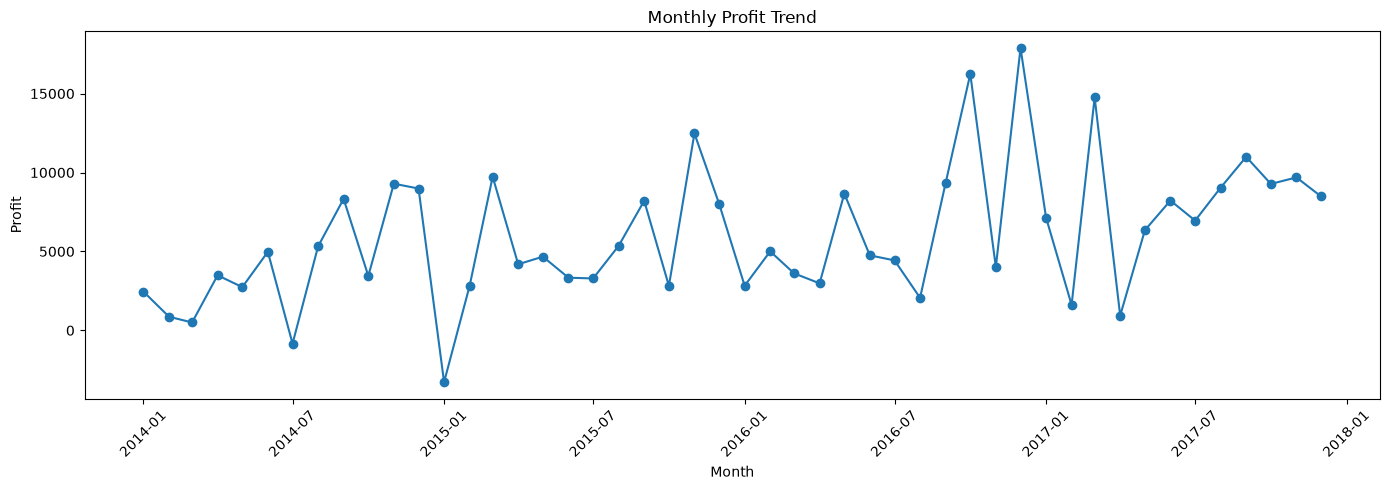

In [9]:
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_performance["month_start"],
    monthly_performance["profit"],
    marker="o"
)

plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Profit")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [10]:
monthly_performance[
    ["month_start", "revenue", "revenue_mom_growth"]
].head(15)

,month_start,revenue,revenue_mom_growth
0,2014-01-01,14236.8950,NaN
1,2014-02-01,4519.8920,-68.252263
2,2014-03-01,55691.0090,1132.131409
3,2014-04-01,28295.3450,-49.192257
4,2014-05-01,23648.2870,-16.423401
5,2014-06-01,34595.1276,46.290205
6,2014-07-01,33946.3930,-1.875220
7,2014-08-01,27909.4685,-17.783699
8,2014-09-01,81777.3508,193.009345
9,2014-10-01,31453.3930,-61.537770


### Best and worst months

In [11]:
best_revenue_month = monthly_performance.loc[
    monthly_performance["revenue"].idxmax()
]

worst_revenue_month = monthly_performance.loc[
    monthly_performance["revenue"].idxmin()
]

best_profit_month = monthly_performance.loc[
    monthly_performance["profit"].idxmax()
]

worst_profit_month = monthly_performance.loc[
    monthly_performance["profit"].idxmin()
]

print("BEST REVENUE MONTH")
display(best_revenue_month)

print("WORST REVENUE MONTH")
display(worst_revenue_month)

print("BEST PROFIT MONTH")
display(best_profit_month)

print("WORST PROFIT MONTH")
display(worst_profit_month)

BEST REVENUE MONTH


month_start           2017-11-01 00:00:00
revenue                        118447.825
profit                          9690.1037
orders                                261
customers                             216
units                                1840
profit_margin                    8.180905
revenue_mom_growth              52.291734
Name: 46, dtype: object

WORST REVENUE MONTH


month_start           2014-02-01 00:00:00
revenue                          4519.892
profit                           862.3084
orders                                 28
customers                              27
units                                 159
profit_margin                   19.078075
revenue_mom_growth             -68.252263
Name: 1, dtype: object

BEST PROFIT MONTH


month_start           2016-12-01 00:00:00
revenue                         96999.043
profit                         17885.3093
orders                                176
customers                             157
units                                1414
profit_margin                   18.438645
revenue_mom_growth              22.146634
Name: 35, dtype: object

WORST PROFIT MONTH


month_start           2015-01-01 00:00:00
revenue                        18174.0756
profit                          -3281.007
orders                                 29
customers                              28
units                                 236
profit_margin                  -18.053226
revenue_mom_growth             -73.867405
Name: 12, dtype: object

## 5. Regional performance

In [12]:
region_performance = (
    df.groupby("region")
      .agg(
          revenue=("revenue", "sum"),
          profit=("profit", "sum"),
          orders=("order_id", "nunique"),
          customers=("customer_id", "nunique"),
          units=("quantity", "sum")
      )
      .reset_index()
)

region_performance["profit_margin"] = (
    region_performance["profit"]
    / region_performance["revenue"]
    * 100
)

region_performance = region_performance.sort_values(
    "revenue",
    ascending=False
)

region_performance

,region,revenue,profit,orders,customers,units,profit_margin
3,West,725457.8245,108418.4489,1611,686,12266,14.944831
1,East,678781.2400,91522.7800,1401,674,10618,13.483399
0,Central,501239.8908,39706.3625,1175,629,8780,7.921629
2,South,391721.9050,46749.4303,822,512,6209,11.934342


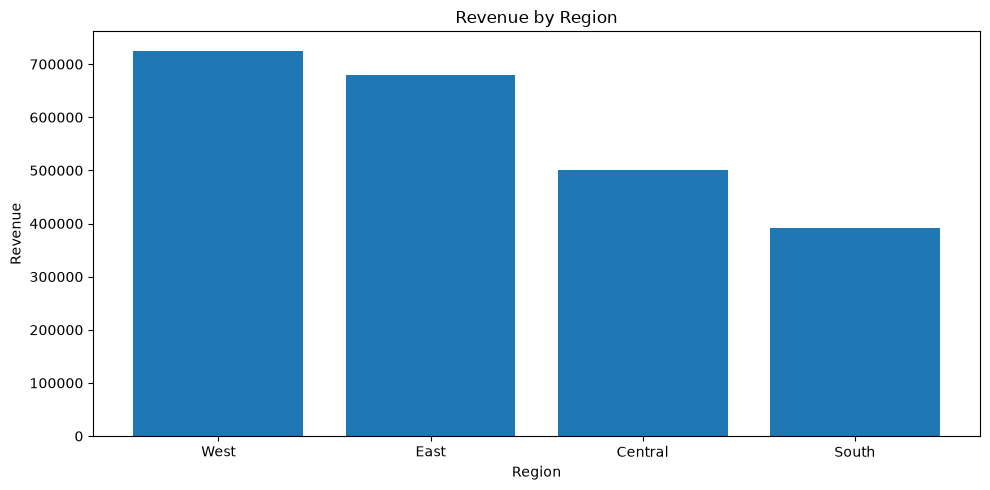

In [13]:
plt.figure(figsize=(10, 5))

plt.bar(
    region_performance["region"],
    region_performance["revenue"]
)

plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue")

plt.tight_layout()
plt.show()

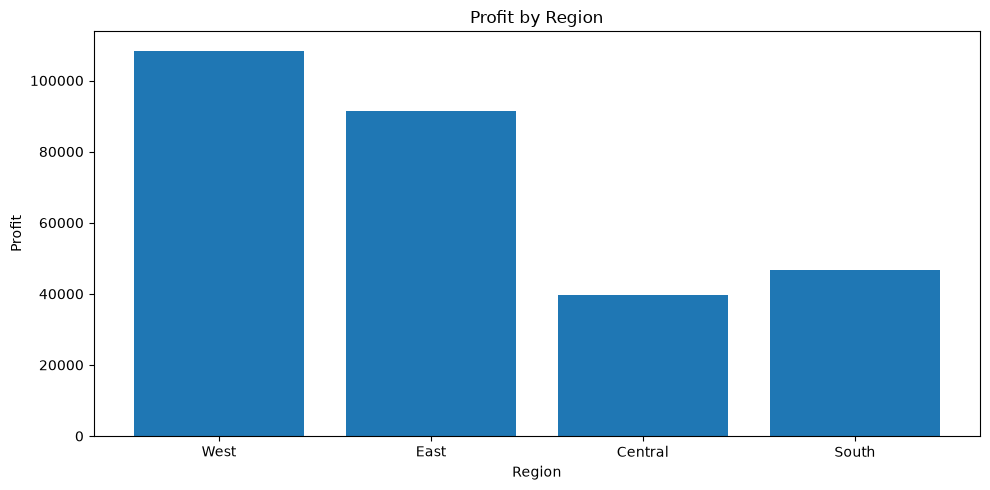

In [14]:
plt.figure(figsize=(10, 5))

plt.bar(
    region_performance["region"],
    region_performance["profit"]
)

plt.title("Profit by Region")
plt.xlabel("Region")
plt.ylabel("Profit")

plt.tight_layout()
plt.show()

First investigation: Discount → Profit


In [40]:
df["discount"].describe()

count    9994.000000
mean        0.156203
std         0.206452
min         0.000000
25%         0.000000
50%         0.200000
75%         0.200000
max         0.800000
Name: discount, dtype: float64

In [41]:
print(
    "Average discount:",
    round(df["discount"].mean() * 100, 2),
    "%"
)

print(
    "Median discount:",
    round(df["discount"].median() * 100, 2),
    "%"
)

Average discount: 15.62 %
Median discount: 20.0 %


In [42]:
bins = [-0.01, 0, 0.10, 0.20, 0.30, 0.50, 1.0]

labels = [
    "0%",
    "1-10%",
    "11-20%",
    "21-30%",
    "31-50%",
    "51%+"
]

df["discount_band"] = pd.cut(
    df["discount"],
    bins=bins,
    labels=labels
)

In [43]:
df["discount_band"].value_counts().sort_index()

discount_band
0%        4798
1-10%       94
11-20%    3709
21-30%     227
31-50%     310
51%+       856
Name: count, dtype: int64

In [44]:
discount_analysis = (
    df.groupby("discount_band", observed=True)
      .agg(
          transactions=("row_id", "count"),
          revenue=("revenue", "sum"),
          profit=("profit", "sum"),
          units=("quantity", "sum")
      )
      .reset_index()
)

In [45]:
discount_analysis["profit_margin"] = (
    discount_analysis["profit"]
    / discount_analysis["revenue"]
    * 100
)

In [46]:
discount_analysis

,discount_band,transactions,revenue,profit,units,profit_margin
0,0%,4798,1.087908e+06,320987.6032,18267,29.505019
1,1-10%,94,5.436935e+04,9029.1770,373,16.607108
2,11-20%,3709,7.921529e+05,91756.2975,13858,11.583155
3,21-30%,227,1.032267e+05,-10369.2774,849,-10.045155
4,31-50%,310,1.953148e+05,-48447.7273,1177,-24.804950
5,51%+,856,6.422874e+04,-76559.0513,3349,-119.197502


In [47]:
loss_by_discount = (
    df[df["profit"] < 0]
    .groupby("discount_band")
    .agg(
        loss_transactions=("row_id", "count"),
        total_loss=("profit", "sum")
    )
    .reset_index()
)

loss_by_discount

,discount_band,loss_transactions,total_loss
0,1-10%,4,-29.2744
1,11-20%,519,-17586.7684
2,21-30%,208,-10777.6879
3,31-50%,284,-51178.5037
4,51%+,856,-76559.0513


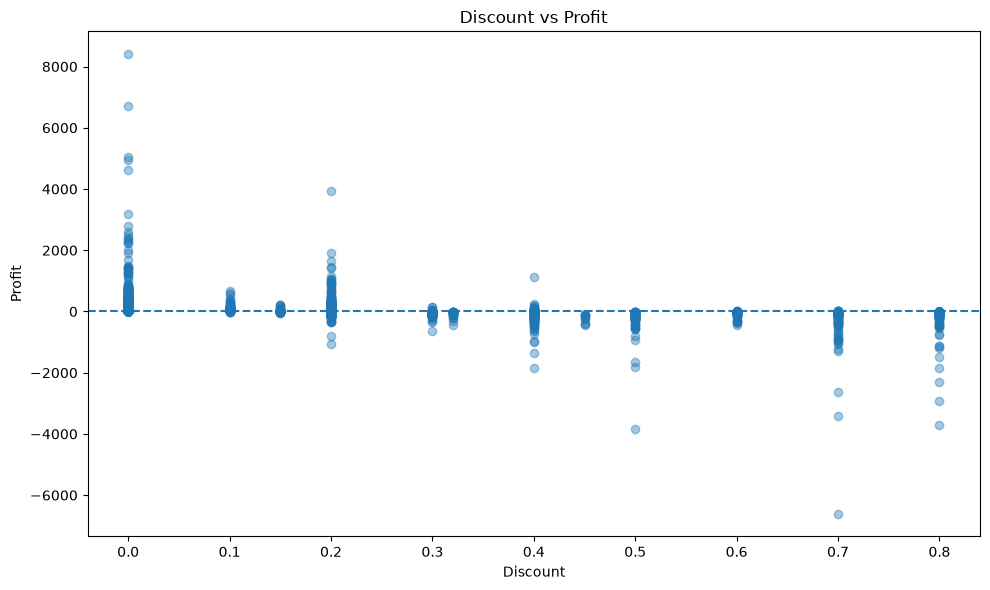

In [48]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["discount"],
    df["profit"],
    alpha=0.4
)

plt.axhline(0, linestyle="--")

plt.title("Discount vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")

plt.tight_layout()
plt.show()

In [50]:
high_discount = df[df["discount"] >= 0.51]

print("Transactions:", len(high_discount))
print("Loss-making transactions:", (high_discount["profit"] < 0).sum())
print("Profitable transactions:", (high_discount["profit"] > 0).sum())
print("Zero-profit transactions:", (high_discount["profit"] == 0).sum())

Transactions: 856
Loss-making transactions: 856
Profitable transactions: 0
Zero-profit transactions: 0


In [51]:
total_negative_profit = df.loc[
    df["profit"] < 0,
    "profit"
].sum()

print("Total negative profit:", total_negative_profit)

Total negative profit: -156131.2857


In [52]:
loss_by_discount["loss_share"] = (
    loss_by_discount["total_loss"].abs()
    / abs(total_negative_profit)
    * 100
)

loss_by_discount

,discount_band,loss_transactions,total_loss,loss_share
0,1-10%,4,-29.2744,0.018750
1,11-20%,519,-17586.7684,11.264090
2,21-30%,208,-10777.6879,6.902965
3,31-50%,284,-51178.5037,32.779147
4,51%+,856,-76559.0513,49.035048


In [53]:
discount_profit_corr = df[
    ["discount", "profit"]
].corr().loc["discount", "profit"]

print(
    "Discount-Profit correlation:",
    round(discount_profit_corr, 3)
)

Discount-Profit correlation: -0.219


C — Product & Sub-category Profitability

In [7]:
category_analysis = (
    df.groupby("category")
      .agg(
          transactions=("row_id", "count"),
          revenue=("revenue", "sum"),
          profit=("profit", "sum"),
          units=("quantity", "sum"),
          avg_discount=("discount", "mean")
      )
      .reset_index()
)

category_analysis["profit_margin"] = (
    category_analysis["profit"]
    / category_analysis["revenue"]
    * 100
)

category_analysis = category_analysis.sort_values(
    "profit",
    ascending=False
)

category_analysis

,category,transactions,revenue,profit,units,avg_discount,profit_margin
2,Technology,1847,836154.0330,145454.9481,6939,0.132323,17.395712
1,Office Supplies,6026,719047.0320,122490.8008,22906,0.157285,17.035158
0,Furniture,2121,741999.7953,18451.2728,8028,0.173923,2.486695


In [8]:
subcategory_analysis = (
    df.groupby("sub_category")
      .agg(
          transactions=("row_id", "count"),
          revenue=("revenue", "sum"),
          profit=("profit", "sum"),
          units=("quantity", "sum"),
          avg_discount=("discount", "mean")
      )
      .reset_index()
)

subcategory_analysis["profit_margin"] = (
    subcategory_analysis["profit"]
    / subcategory_analysis["revenue"]
    * 100
)

subcategory_analysis = subcategory_analysis.sort_values(
    "profit",
    ascending=False
)

subcategory_analysis

,sub_category,transactions,revenue,profit,units,avg_discount,profit_margin
6,Copiers,68,149528.0300,55617.8249,234,0.161765,37.195585
13,Phones,889,330007.0540,44515.7306,3289,0.154556,13.489327
0,Accessories,775,167380.3180,41936.6357,2976,0.078452,25.054700
12,Paper,1370,78479.2060,34053.5693,5178,0.074891,43.391837
3,Binders,1523,203412.7330,30221.7633,5974,0.372292,14.857361
5,Chairs,617,328449.1030,26590.1663,2356,0.170178,8.095673
14,Storage,846,223843.6080,21278.8264,3158,0.074704,9.506113
1,Appliances,466,107532.1610,18138.0054,1729,0.166524,16.867517
9,Furnishings,957,91705.1640,13059.1436,3563,0.138349,14.240358
7,Envelopes,254,16476.4020,6964.1767,906,0.080315,42.267582


In [9]:
print("Unique sub-categories in df:")
print(df["sub_category"].nunique())

print("\nAll sub-categories:")
print(sorted(df["sub_category"].unique()))

Unique sub-categories in df:
17

All sub-categories:
['Accessories', 'Appliances', 'Art', 'Binders', 'Bookcases', 'Chairs', 'Copiers', 'Envelopes', 'Fasteners', 'Furnishings', 'Labels', 'Machines', 'Paper', 'Phones', 'Storage', 'Supplies', 'Tables']


In [10]:
print(
    "\nSub-category transaction counts:"
)

print(
    df["sub_category"]
    .value_counts()
    .sort_index()
)


Sub-category transaction counts:
sub_category
Accessories     775
Appliances      466
Art             796
Binders        1523
Bookcases       228
Chairs          617
Copiers          68
Envelopes       254
Fasteners       217
Furnishings     957
Labels          364
Machines        115
Paper          1370
Phones          889
Storage         846
Supplies        190
Tables          319
Name: count, dtype: int64


In [11]:
print(
    "\nSub-categories by category:"
)

print(
    df.groupby("category")["sub_category"]
      .unique()
)


Sub-categories by category:
category
Furniture                   [Bookcases, Chairs, Tables, Furnishings]
Office Supplies    [Labels, Storage, Art, Binders, Appliances, Pa...
Technology                  [Phones, Accessories, Machines, Copiers]
Name: sub_category, dtype: object


In [12]:
print(
    "Rows in subcategory_analysis:",
    len(subcategory_analysis)
)

Rows in subcategory_analysis: 17


In [13]:
df["sub_category"].nunique()

17

In [14]:
df["sub_category"].nunique()

17

In [15]:
sorted(df["sub_category"].unique())

['Accessories',
 'Appliances',
 'Art',
 'Binders',
 'Bookcases',
 'Chairs',
 'Copiers',
 'Envelopes',
 'Fasteners',
 'Furnishings',
 'Labels',
 'Machines',
 'Paper',
 'Phones',
 'Storage',
 'Supplies',
 'Tables']

In [16]:
df["sub_category"].value_counts().sort_index()

sub_category
Accessories     775
Appliances      466
Art             796
Binders        1523
Bookcases       228
Chairs          617
Copiers          68
Envelopes       254
Fasteners       217
Furnishings     957
Labels          364
Machines        115
Paper          1370
Phones          889
Storage         846
Supplies        190
Tables          319
Name: count, dtype: int64

In [17]:
df.groupby("category")["sub_category"].unique()

category
Furniture                   [Bookcases, Chairs, Tables, Furnishings]
Office Supplies    [Labels, Storage, Art, Binders, Appliances, Pa...
Technology                  [Phones, Accessories, Machines, Copiers]
Name: sub_category, dtype: object

C.3 — Now we drill into individual products

In [18]:
product_analysis = (
    df.groupby(["product_id", "product_name"])
      .agg(
          transactions=("row_id", "count"),
          revenue=("revenue", "sum"),
          profit=("profit", "sum"),
          units=("quantity", "sum"),
          avg_discount=("discount", "mean")
      )
      .reset_index()
)

product_analysis["profit_margin"] = (
    product_analysis["profit"]
    / product_analysis["revenue"]
    * 100
)

In [19]:
top_profit_products = (
    product_analysis
    .sort_values("profit", ascending=False)
    .head(10)
)

top_profit_products

,product_id,product_name,transactions,revenue,profit,units,avg_discount,profit_margin
1640,TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,5,61599.824,25199.9280,20,0.120000,40.909091
787,OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Bin...,10,27453.384,7753.0390,31,0.240000,28.240741
1630,TEC-CO-10001449,Hewlett Packard LaserJet 3310 Copier,8,18839.686,6983.8836,38,0.200000,37.070064
1637,TEC-CO-10003763,Canon PC1060 Personal Laser Copier,4,11619.834,4570.9347,19,0.150000,39.337349
1657,TEC-MA-10001127,HP Designjet T520 Inkjet Large Format Printer ...,3,18374.895,4094.9766,12,0.166667,22.285714
1693,TEC-MA-10003979,Ativa V4110MDD Micro-Cut Shredder,2,7699.890,3772.9461,11,0.000000,49.000000
1656,TEC-MA-10001047,"3D Systems Cube Printer, 2nd Generation, Magenta",2,14299.890,3717.9714,11,0.000000,26.000000
1541,TEC-AC-10002049,Plantronics Savi W720 Multi-Device Wireless He...,7,9367.290,3696.2820,24,0.057143,39.459459
692,OFF-BI-10001120,Ibico EPK-21 Electric Binding System,3,15875.916,3345.2823,13,0.333333,21.071429
1643,TEC-MA-10000045,Zebra ZM400 Thermal Label Printer,2,6965.700,3343.5360,6,0.000000,48.000000


In [20]:
top_loss_products = (
    product_analysis
    .sort_values("profit", ascending=True)
    .head(10)
)

top_loss_products

,product_id,product_name,transactions,revenue,profit,units,avg_discount,profit_margin
1645,TEC-MA-10000418,Cubify CubeX 3D Printer Double Head Print,3,11099.963,-8879.9704,9,0.533333,-80.000000
1650,TEC-MA-10000822,Lexmark MX611dhe Monochrome Laser Printer,4,16829.901,-4589.9730,18,0.400000,-27.272727
1696,TEC-MA-10004125,Cubify CubeX 3D Printer Triple Head Print,1,7999.980,-3839.9904,4,0.500000,-48.000000
326,FUR-TA-10000198,Chromcraft Bull-Nose Wood Oval Conference Tabl...,5,9917.640,-2876.1156,27,0.280000,-29.000000
344,FUR-TA-10001889,Bush Advantage Collection Racetrack Conference...,7,9544.725,-1934.3976,33,0.350000,-20.266667
858,OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,6,17965.068,-1878.1662,27,0.450000,-10.454545
1669,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,1,22638.480,-1811.0784,6,0.500000,-8.000000
1465,OFF-SU-10002881,Martin Yale Chadless Opener Electric Letter Op...,6,16656.200,-1299.1836,22,0.100000,-7.800000
346,FUR-TA-10001950,Balt Solid Wood Round Tables,4,6518.754,-1201.0581,19,0.200000,-18.424658
375,FUR-TA-10004289,BoxOffice By Design Rectangular and Half-Moon ...,3,1706.250,-1148.4375,15,0.483333,-67.307692


In [21]:
top_revenue_products = (
    product_analysis
    .sort_values("revenue", ascending=False)
    .head(10)
)

top_revenue_products

,product_id,product_name,transactions,revenue,profit,units,avg_discount,profit_margin
1640,TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,5,61599.824,2.519993e+04,20,0.120000,4.090909e+01
787,OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Bin...,10,27453.384,7.753039e+03,31,0.240000,2.824074e+01
1669,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,1,22638.480,-1.811078e+03,6,0.500000,-8.000000e+00
82,FUR-CH-10002024,HON 5400 Series Task Chairs for Big and Tall,8,21870.576,5.684342e-14,39,0.200000,2.599082e-16
701,OFF-BI-10001359,GBC DocuBind TL300 Electric Binding System,11,19823.479,2.233505e+03,37,0.300000,1.126697e+01
667,OFF-BI-10000545,GBC Ibimaster 500 Manual ProClick Binding System,9,19024.500,7.609800e+02,48,0.522222,4.000000e+00
1630,TEC-CO-10001449,Hewlett Packard LaserJet 3310 Copier,8,18839.686,6.983884e+03,38,0.200000,3.707006e+01
1657,TEC-MA-10001127,HP Designjet T520 Inkjet Large Format Printer ...,3,18374.895,4.094977e+03,12,0.166667,2.228571e+01
858,OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,6,17965.068,-1.878166e+03,27,0.450000,-1.045455e+01
1443,OFF-SU-10000151,High Speed Automatic Electric Letter Opener,3,17030.312,-2.620048e+02,11,0.066667,-1.538462e+00


In [22]:
high_discount_products = (
    product_analysis
    .sort_values("avg_discount", ascending=False)
    .head(10)
)

high_discount_products

,product_id,product_name,transactions,revenue,profit,units,avg_discount,profit_margin
427,OFF-AP-10002203,Eureka Disposable Bags for Sanitaire Vibra Gro...,1,1.624,-4.4660,2,0.800000,-275.000000
775,OFF-BI-10003166,GBC Plasticlear Binding Covers,7,68.880,-68.4208,23,0.728571,-99.333333
675,OFF-BI-10000778,GBC VeloBinder Electric Binding Machine,4,496.018,-411.3320,15,0.725000,-82.926829
1685,TEC-MA-10003337,Okidata B401 Printer,1,179.991,-251.9874,3,0.700000,-140.000000
1652,TEC-MA-10000904,"Brother MFC-9340CDW LED All-In-One Printer, Co...",1,341.991,-319.1916,3,0.700000,-93.333333
1695,TEC-MA-10004086,Plantronics Single Ear Headset,1,29.925,-21.9450,5,0.700000,-73.333333
1662,TEC-MA-10001695,Zebra GK420t Direct Thermal/Thermal Transfer P...,1,703.710,-938.2800,6,0.700000,-133.333333
1671,TEC-MA-10002694,Hewlett-Packard Deskjet F4180 All-in-One Color...,1,101.994,-71.3958,2,0.700000,-70.000000
1689,TEC-MA-10003589,Cisco 8961 IP Phone Charcoal,1,224.937,-164.9538,3,0.700000,-73.333333
1661,TEC-MA-10001681,Lexmark MarkNet N8150 Wireless Print Server,2,723.510,-506.4570,6,0.700000,-70.000000


C.4 — Loss Concentration Analysis

In [23]:
loss_products = (
    product_analysis[
        product_analysis["profit"] < 0
    ]
    .sort_values("profit")
    .copy()
)

loss_products["cumulative_loss"] = (
    loss_products["profit"].abs().cumsum()
)

total_product_loss = loss_products["profit"].abs().sum()

loss_products["cumulative_loss_pct"] = (
    loss_products["cumulative_loss"]
    / total_product_loss
    * 100
)

loss_products.head(20)

,product_id,product_name,transactions,revenue,profit,units,avg_discount,profit_margin,cumulative_loss,cumulative_loss_pct
1645,TEC-MA-10000418,Cubify CubeX 3D Printer Double Head Print,3,11099.9630,-8879.9704,9,0.533333,-80.000000,8879.9704,11.518664
1650,TEC-MA-10000822,Lexmark MX611dhe Monochrome Laser Printer,4,16829.9010,-4589.9730,18,0.400000,-27.272727,13469.9434,17.472553
1696,TEC-MA-10004125,Cubify CubeX 3D Printer Triple Head Print,1,7999.9800,-3839.9904,4,0.500000,-48.000000,17309.9338,22.453601
326,FUR-TA-10000198,Chromcraft Bull-Nose Wood Oval Conference Tabl...,5,9917.6400,-2876.1156,27,0.280000,-29.000000,20186.0494,26.184358
344,FUR-TA-10001889,Bush Advantage Collection Racetrack Conference...,7,9544.7250,-1934.3976,33,0.350000,-20.266667,22120.4470,28.693564
858,OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,6,17965.0680,-1878.1662,27,0.450000,-10.454545,23998.6132,31.129829
1669,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,1,22638.4800,-1811.0784,6,0.500000,-8.000000,25809.6916,33.479072
1465,OFF-SU-10002881,Martin Yale Chadless Opener Electric Letter Op...,6,16656.2000,-1299.1836,22,0.100000,-7.800000,27108.8752,35.164309
346,FUR-TA-10001950,Balt Solid Wood Round Tables,4,6518.7540,-1201.0581,19,0.200000,-18.424658,28309.9333,36.722263
375,FUR-TA-10004289,BoxOffice By Design Rectangular and Half-Moon ...,3,1706.2500,-1148.4375,15,0.483333,-67.307692,29458.3708,38.211960


In [24]:
for threshold in [50, 80, 90]:
    count = (
        loss_products["cumulative_loss_pct"] <= threshold
    ).sum() + 1

    print(
        f"Products responsible for first {threshold}% of losses:",
        count
    )

Products responsible for first 50% of losses: 20
Products responsible for first 80% of losses: 69
Products responsible for first 90% of losses: 106


In [25]:
print("Total loss-making products:", len(loss_products))
print("Total products:", len(product_analysis))

Total loss-making products: 306
Total products: 1894


In [26]:
print("Unique product IDs:", df["product_id"].nunique())

print(
    "Unique product ID + name combinations:",
    df[["product_id", "product_name"]].drop_duplicates().shape[0]
)

print(
    "Rows in product_analysis:",
    len(product_analysis)
)

Unique product IDs: 1862
Unique product ID + name combinations: 1894
Rows in product_analysis: 1894


In [27]:
product_name_check = (
    df.groupby("product_id")["product_name"]
      .nunique()
      .sort_values(ascending=False)
)

print(
    "Product IDs with multiple names:",
    (product_name_check > 1).sum()
)

product_name_check[product_name_check > 1]

Product IDs with multiple names: 32


product_id
OFF-AR-10001149    2
FUR-FU-10001473    2
FUR-FU-10004017    2
OFF-BI-10004632    2
FUR-FU-10004270    2
FUR-CH-10001146    2
FUR-FU-10004848    2
FUR-FU-10004864    2
OFF-AP-10000576    2
FUR-FU-10004091    2
OFF-BI-10002026    2
OFF-BI-10004654    2
OFF-PA-10000357    2
OFF-PA-10000477    2
OFF-PA-10000659    2
OFF-PA-10001166    2
OFF-PA-10001970    2
OFF-PA-10002195    2
OFF-PA-10002377    2
OFF-PA-10003022    2
OFF-ST-10001228    2
OFF-ST-10004950    2
TEC-AC-10002049    2
TEC-AC-10002550    2
TEC-AC-10003832    2
TEC-MA-10001148    2
TEC-PH-10001530    2
TEC-PH-10001795    2
TEC-PH-10002200    2
TEC-PH-10002310    2
FUR-BO-10002213    2
TEC-PH-10004531    2
Name: product_name, dtype: int64

2D — Regional & Customer Segment Analysis

In [28]:
region_analysis = (
    df.groupby("region")
      .agg(
          transactions=("row_id", "count"),
          revenue=("revenue", "sum"),
          profit=("profit", "sum"),
          orders=("order_id", "nunique"),
          customers=("customer_id", "nunique"),
          units=("quantity", "sum"),
          avg_discount=("discount", "mean")
      )
      .reset_index()
)

region_analysis["profit_margin"] = (
    region_analysis["profit"]
    / region_analysis["revenue"]
    * 100
)

region_analysis["revenue_share"] = (
    region_analysis["revenue"]
    / region_analysis["revenue"].sum()
    * 100
)

region_analysis["profit_share"] = (
    region_analysis["profit"]
    / region_analysis["profit"].sum()
    * 100
)

region_analysis.sort_values(
    "profit",
    ascending=False
)

,region,transactions,revenue,profit,orders,customers,units,avg_discount,profit_margin,revenue_share,profit_share
3,West,3203,725457.8245,108418.4489,1611,686,12266,0.109335,14.944831,31.580078,37.855997
1,East,2848,678781.2400,91522.7800,1401,674,10618,0.145365,13.483399,29.548188,31.956610
2,South,1620,391721.9050,46749.4303,822,512,6209,0.147253,11.934342,17.052140,16.323295
0,Central,2323,501239.8908,39706.3625,1175,629,8780,0.240353,7.921629,21.819594,13.864098


In [29]:
region_category = (
    df.groupby(["region", "category"])
      .agg(
          revenue=("revenue", "sum"),
          profit=("profit", "sum"),
          transactions=("row_id", "count"),
          avg_discount=("discount", "mean")
      )
      .reset_index()
)

region_category["profit_margin"] = (
    region_category["profit"]
    / region_category["revenue"]
    * 100
)

region_category

,region,category,revenue,profit,transactions,avg_discount,profit_margin
0,Central,Furniture,163797.1638,-2871.0494,481,0.297380,-1.752808
1,Central,Office Supplies,167026.4150,8879.9799,1422,0.252743,5.316512
2,Central,Technology,170416.3120,33697.4320,420,0.133095,19.773595
3,East,Furniture,208291.2040,3046.1658,601,0.154077,1.462455
4,East,Office Supplies,205516.0550,41014.5791,1712,0.142932,19.956873
5,East,Technology,264973.9810,47462.0351,535,0.143364,17.911961
6,South,Furniture,117298.6840,6771.2061,332,0.121536,5.772619
7,South,Office Supplies,125651.3130,19986.3928,995,0.167437,15.906235
8,South,Technology,148771.9080,19991.8314,293,0.107850,13.437908
9,West,Furniture,252612.7435,11504.9503,707,0.131400,4.554382


In [30]:
segment_analysis = (
    df.groupby("segment")
      .agg(
          transactions=("row_id", "count"),
          revenue=("revenue", "sum"),
          profit=("profit", "sum"),
          orders=("order_id", "nunique"),
          customers=("customer_id", "nunique"),
          units=("quantity", "sum"),
          avg_discount=("discount", "mean")
      )
      .reset_index()
)

segment_analysis["profit_margin"] = (
    segment_analysis["profit"]
    / segment_analysis["revenue"]
    * 100
)

segment_analysis["revenue_share"] = (
    segment_analysis["revenue"]
    / segment_analysis["revenue"].sum()
    * 100
)

segment_analysis["profit_share"] = (
    segment_analysis["profit"]
    / segment_analysis["profit"].sum()
    * 100
)

segment_analysis.sort_values(
    "profit",
    ascending=False
)

,segment,transactions,revenue,profit,orders,customers,units,avg_discount,profit_margin,revenue_share,profit_share
0,Consumer,5191,1.161401e+06,134119.2092,2586,409,19521,0.158141,11.548050,50.557240,46.829820
1,Corporate,3020,7.061464e+05,91979.1340,1514,236,11608,0.158228,13.025506,30.739426,32.115953
2,Home Office,1783,4.296531e+05,60298.6785,909,148,6744,0.147128,14.034269,18.703334,21.054227


In [31]:
segment_category = (
    df.groupby(["segment", "category"])
      .agg(
          revenue=("revenue", "sum"),
          profit=("profit", "sum"),
          transactions=("row_id", "count"),
          avg_discount=("discount", "mean")
      )
      .reset_index()
)

segment_category["profit_margin"] = (
    segment_category["profit"]
    / segment_category["revenue"]
    * 100
)

segment_category

,segment,category,revenue,profit,transactions,avg_discount,profit_margin
0,Consumer,Furniture,391049.3120,6991.0786,1113,0.176739,1.787774
1,Consumer,Office Supplies,363952.1360,56330.3210,3127,0.158746,15.477398
2,Consumer,Technology,406399.8970,70797.8096,951,0.134385,17.420725
3,Corporate,Furniture,229019.7858,7584.8158,646,0.174071,3.311860
4,Corporate,Office Supplies,230676.4620,40227.3202,1820,0.160604,17.438849
5,Corporate,Technology,246450.1190,44166.9980,554,0.131949,17.921273
6,Home Office,Furniture,121930.6975,3875.3784,362,0.165000,3.178345
7,Home Office,Office Supplies,124418.4340,25933.1596,1079,0.147451,20.843503
8,Home Office,Technology,183304.0170,30490.1405,342,0.127193,16.633646


E1 — Build Customer Profitability Table

In [32]:
customer_analysis = (
    df.groupby(["customer_id", "customer_name"])
      .agg(
          transactions=("row_id", "count"),
          revenue=("revenue", "sum"),
          profit=("profit", "sum"),
          orders=("order_id", "nunique"),
          units=("quantity", "sum"),
          avg_discount=("discount", "mean")
      )
      .reset_index()
)

customer_analysis["profit_margin"] = (
    customer_analysis["profit"]
    / customer_analysis["revenue"]
    * 100
)

customer_analysis["avg_order_value"] = (
    customer_analysis["revenue"]
    / customer_analysis["orders"]
)

customer_analysis["revenue_share"] = (
    customer_analysis["revenue"]
    / customer_analysis["revenue"].sum()
    * 100
)

customer_analysis["profit_share"] = (
    customer_analysis["profit"]
    / customer_analysis["profit"].sum()
    * 100
)

In [33]:
customer_analysis.head()

,customer_id,customer_name,transactions,revenue,profit,orders,units,avg_discount,profit_margin,avg_order_value,revenue_share,profit_share
0,AA-10315,Alex Avila,11,5563.560,-362.8825,5,30,0.090909,-6.522487,1112.712000,0.242189,-0.126706
1,AA-10375,Allen Armold,15,1056.390,277.3824,9,41,0.080000,26.257575,117.376667,0.045986,0.096852
2,AA-10480,Andrew Allen,12,1790.512,435.8274,4,36,0.016667,24.340937,447.628000,0.077943,0.152176
3,AA-10645,Anna Andreadi,18,5086.935,857.8033,6,64,0.063889,16.862871,847.822500,0.221441,0.299515
4,AB-10015,Aaron Bergman,6,886.156,129.3465,3,13,0.066667,14.596358,295.385333,0.038575,0.045163


In [34]:
top_customer_revenue = (
    customer_analysis
    .sort_values("revenue", ascending=False)
    .head(10)
)

top_customer_revenue

,customer_id,customer_name,transactions,revenue,profit,orders,units,avg_discount,profit_margin,avg_order_value,revenue_share,profit_share
700,SM-20320,Sean Miller,15,25043.050,-1980.7393,5,50,0.246667,-7.909337,5008.610000,1.090155,-0.691606
741,TC-20980,Tamara Chand,12,19052.218,8981.3239,5,42,0.116667,47.140569,3810.443600,0.829367,3.135970
621,RB-19360,Raymond Buch,18,15117.339,6976.0959,6,71,0.094444,46.146322,2519.556500,0.658076,2.435813
730,TA-21385,Tom Ashbrook,10,14595.620,4703.7883,4,36,0.080000,32.227396,3648.905000,0.635365,1.642401
6,AB-10105,Adrian Barton,20,14473.571,5444.8055,10,73,0.240000,37.618950,1447.357100,0.630052,1.901139
434,KL-16645,Ken Lonsdale,29,14175.229,806.8550,12,113,0.200000,5.692007,1181.269083,0.617065,0.281726
669,SC-20095,Sanjit Chand,22,14142.334,5757.4119,9,87,0.063636,40.710479,1571.370444,0.615633,2.010290
327,HL-15040,Hunter Lopez,11,12873.298,5622.4292,6,50,0.018182,43.675127,2145.549667,0.560391,1.963159
683,SE-20110,Sanjit Engle,19,12209.438,2650.6769,11,78,0.110526,21.710065,1109.948909,0.531492,0.925525
131,CC-12370,Christopher Conant,11,12129.072,2177.0493,5,34,0.281818,17.949018,2425.814400,0.527994,0.760151


In [35]:
top_customer_profit = (
    customer_analysis
    .sort_values("profit", ascending=False)
    .head(10)
)

top_customer_profit

,customer_id,customer_name,transactions,revenue,profit,orders,units,avg_discount,profit_margin,avg_order_value,revenue_share,profit_share
741,TC-20980,Tamara Chand,12,19052.218,8981.3239,5,42,0.116667,47.140569,3810.443600,0.829367,3.135970
621,RB-19360,Raymond Buch,18,15117.339,6976.0959,6,71,0.094444,46.146322,2519.556500,0.658076,2.435813
669,SC-20095,Sanjit Chand,22,14142.334,5757.4119,9,87,0.063636,40.710479,1571.370444,0.615633,2.010290
327,HL-15040,Hunter Lopez,11,12873.298,5622.4292,6,50,0.018182,43.675127,2145.549667,0.560391,1.963159
6,AB-10105,Adrian Barton,20,14473.571,5444.8055,10,73,0.240000,37.618950,1447.357100,0.630052,1.901139
730,TA-21385,Tom Ashbrook,10,14595.620,4703.7883,4,36,0.080000,32.227396,3648.905000,0.635365,1.642401
160,CM-12385,Christopher Martinez,10,8954.020,3899.8904,4,34,0.120000,43.554631,2238.505000,0.389780,1.361708
424,KD-16495,Keith Dawkins,28,8181.256,3038.6254,12,84,0.087500,37.141307,681.771333,0.356140,1.060984
48,AR-10540,Andy Reiter,9,6608.448,2884.6208,6,33,0.066667,43.650503,1101.408000,0.287674,1.007210
234,DR-12940,Daniel Raglin,13,8350.868,2869.0760,8,57,0.153846,34.356620,1043.858500,0.363524,1.001783


In [36]:
loss_customers = (
    customer_analysis[
        customer_analysis["profit"] < 0
    ]
    .sort_values("profit")
)

loss_customers.head(10)

,customer_id,customer_name,transactions,revenue,profit,orders,units,avg_discount,profit_margin,avg_order_value,revenue_share,profit_share
180,CS-12505,Cindy Stewart,9,5690.055,-6626.3895,6,40,0.200000,-116.455632,948.342500,0.247695,-2.313708
310,GT-14635,Grant Thornton,6,9351.212,-4108.6589,3,26,0.250000,-43.937181,3117.070667,0.407070,-1.434603
459,LF-17185,Luke Foster,16,3930.509,-3583.9770,7,69,0.318750,-91.183534,561.501286,0.171100,-1.251402
711,SR-20425,Sharelle Roach,9,3233.481,-3333.9144,5,34,0.366667,-103.106046,646.696200,0.140757,-1.164088
322,HG-14965,Henry Goldwyn,17,3247.642,-2797.9635,12,68,0.170588,-86.153692,270.636833,0.141374,-0.976953
555,NC-18415,Nathan Cano,14,2218.990,-2204.8072,6,38,0.264286,-99.360844,369.831667,0.096595,-0.769843
666,SB-20290,Sean Braxton,17,8057.891,-2082.7451,7,84,0.241176,-25.847273,1151.127286,0.350770,-0.727223
700,SM-20320,Sean Miller,15,25043.050,-1980.7393,5,50,0.246667,-7.909337,5008.610000,1.090155,-0.691606
165,CP-12340,Christine Phan,15,5888.275,-1850.3029,8,59,0.213333,-31.423514,736.034375,0.256324,-0.646062
560,NF-18385,Natalie Fritzler,14,8322.826,-1695.9714,7,52,0.250000,-20.377350,1188.975143,0.362303,-0.592175


In [37]:
print(
    "Total customers:",
    len(customer_analysis)
)

print(
    "Loss-making customers:",
    len(loss_customers)
)

print(
    "Loss-making customer rate:",
    len(loss_customers) / len(customer_analysis) * 100,
    "%"
)

Total customers: 793
Loss-making customers: 155
Loss-making customer rate: 19.546027742749054 %


In [38]:
loss_customers = loss_customers.copy()

loss_customers["cumulative_loss"] = (
    loss_customers["profit"].abs().cumsum()
)

total_customer_loss = (
    loss_customers["profit"].abs().sum()
)

loss_customers["cumulative_loss_pct"] = (
    loss_customers["cumulative_loss"]
    / total_customer_loss
    * 100
)

In [39]:
for threshold in [50, 80, 90]:
    count = (
        loss_customers["cumulative_loss_pct"] <= threshold
    ).sum() + 1

    print(
        f"Customers responsible for first {threshold}% of losses:",
        count
    )

Customers responsible for first 50% of losses: 14
Customers responsible for first 80% of losses: 47
Customers responsible for first 90% of losses: 72


In [40]:
customer_summary = customer_analysis[
    [
        "customer_id",
        "customer_name",
        "revenue",
        "profit",
        "profit_margin",
        "orders",
        "avg_order_value",
        "units",
        "avg_discount"
    ]
].copy()

In [41]:
customer_summary.sort_values(
    "avg_order_value",
    ascending=False
).head(10)

,customer_id,customer_name,revenue,profit,profit_margin,orders,avg_order_value,units,avg_discount
700,SM-20320,Sean Miller,25043.050,-1980.7393,-7.909337,5,5008.610000,50,0.246667
741,TC-20980,Tamara Chand,19052.218,8981.3239,47.140569,5,3810.443600,42,0.116667
730,TA-21385,Tom Ashbrook,14595.620,4703.7883,32.227396,4,3648.905000,36,0.080000
310,GT-14635,Grant Thornton,9351.212,-4108.6589,-43.937181,3,3117.070667,26,0.250000
90,BM-11140,Becky Martin,11789.630,-1659.9581,-14.079815,4,2947.407500,64,0.168750
547,MW-18235,Mitch Willingham,5253.876,1665.5160,31.700710,2,2626.938000,13,0.066667
621,RB-19360,Raymond Buch,15117.339,6976.0959,46.146322,6,2519.556500,71,0.094444
131,CC-12370,Christopher Conant,12129.072,2177.0493,17.949018,5,2425.814400,34,0.281818
588,PF-19120,Peter Fuller,9062.864,-614.2943,-6.778148,4,2265.716000,75,0.121053
160,CM-12385,Christopher Martinez,8954.020,3899.8904,43.554631,4,2238.505000,34,0.120000
